<a href="https://colab.research.google.com/github/yashikasgh/flyrank-ml-internship/blob/main/work/notebooks/w04_signal_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/yashikasgh/flyrank-ml-internship/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions

*Look before deciding: distributions of your key fields. Note the heavy tails.*

Dataset shape: (30000, 44)
Number of columns: 44


,count,mean,std,min,25%,50%,75%,max
search_volume,27532.0,158.882391,1518.270825,0.0,0.0,10.00,20.00,74000.00
competition,27532.0,0.146954,0.285241,0.0,0.0,0.00,0.13,1.00
cpc,27532.0,0.485342,2.101560,0.0,0.0,0.00,0.00,100.36
word_count,22301.0,3107.760325,1452.382598,8.0,2413.0,2877.00,3666.00,9546.00
char_count,22301.0,20665.277835,10115.344042,40.0,15644.0,19116.00,24011.00,111158.00
content_age_days,30000.0,256.167800,132.707930,90.0,132.0,236.00,333.00,564.00
days_since_last_update,30000.0,46.098300,42.078709,1.0,20.0,20.00,104.00,373.00
impressions_90d,30000.0,5200.366300,16838.019547,1.0,81.0,731.00,3615.25,517715.00
ctr,30000.0,0.510733,3.279162,0.0,0.0,0.07,0.29,100.00
trend_pct,26612.0,-4.785969,473.861780,-100.0,-62.6,-33.50,0.00,44900.00



Missing values:


,missing_count
search_volume,2468
competition,2468
cpc,2468
word_count,7699
char_count,7699
content_age_days,0
days_since_last_update,0
impressions_90d,0
ctr,0
trend_pct,3388


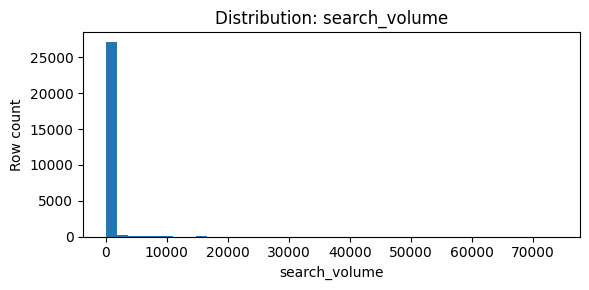

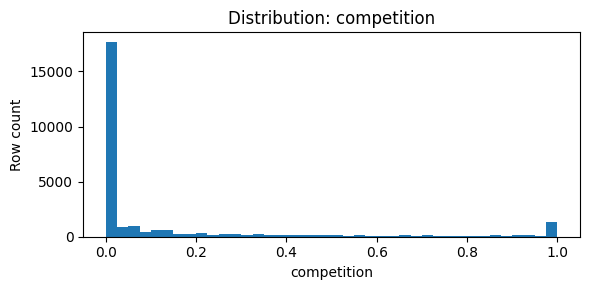

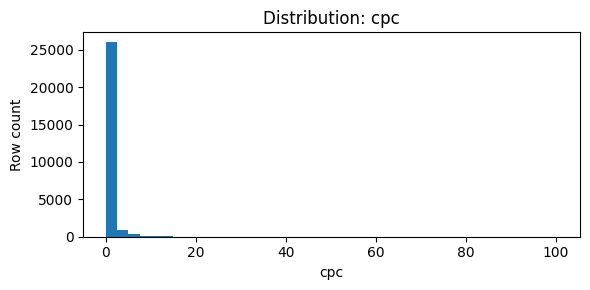

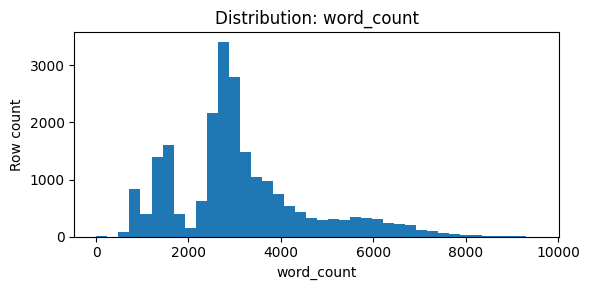

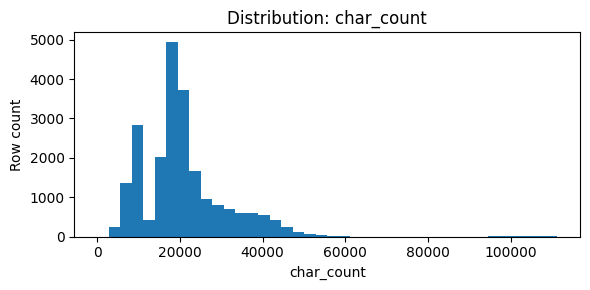

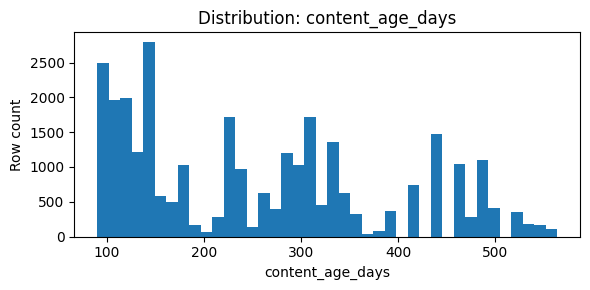

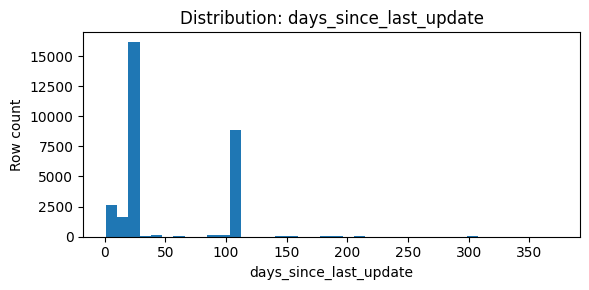

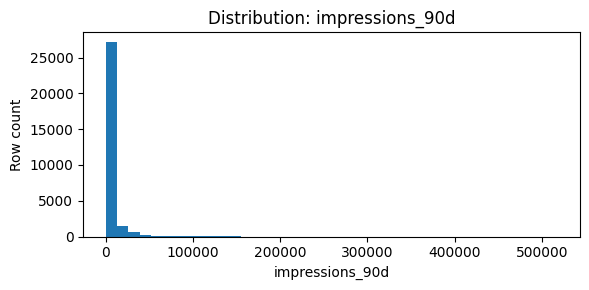

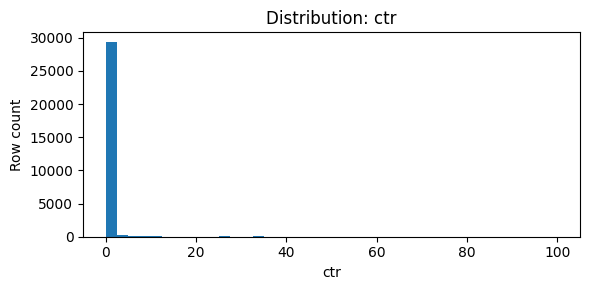

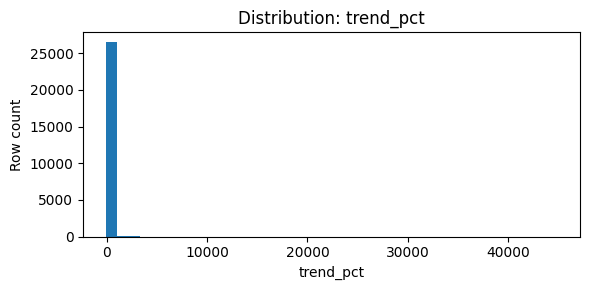

Distribution inspection complete.


In [7]:

# ML-06: Load the anonymized dataset and inspect distributions

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

if "df" not in globals():
    from google.colab import files
    uploaded = files.upload()
    csv_files = [name for name in uploaded if name.endswith(".csv")]

    if not csv_files:
        raise ValueError("Please upload content_refresh_anonymized.csv")

    df = pd.read_csv(csv_files[0])

print("Dataset shape:", df.shape)
print("Number of columns:", len(df.columns))

# Inspect important numeric signals that exist in this dataset.
numeric_candidates = [
    "search_volume",
    "competition",
    "cpc",
    "word_count",
    "char_count",
    "content_age_days",
    "days_since_last_update",
    "impressions_90d",
    "ctr",
    "trend_pct",
]

numeric_cols = [c for c in numeric_candidates if c in df.columns]

display(df[numeric_cols].describe().T)

print("\nMissing values:")
display(df[numeric_cols].isna().sum().rename("missing_count").to_frame())

# Plot distributions using histograms.
for col in numeric_cols:
    values = pd.to_numeric(df[col], errors="coerce").dropna()
    if len(values) == 0:
        continue

    plt.figure(figsize=(6, 3))
    plt.hist(values, bins=40)
    plt.title(f"Distribution: {col}")
    plt.xlabel(col)
    plt.ylabel("Row count")
    plt.tight_layout()
    plt.show()

print("Distribution inspection complete.")



### Distribution observations

The dataset contains anonymized content-level records. Numeric distributions and missing-value counts are inspected before testing individual signals. Histograms help identify skew, outliers, and concentrated ranges; summary statistics alone do not establish that a signal predicts content performance.

Interpretation will be based on the observed outputs from this notebook. No direction of association is assumed before the signal tests are run.


## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*

In [8]:

# ML-06: Test three candidate signals against the down-trend label

if "df" not in globals():
    raise RuntimeError("Run Section 1 first to load df.")

if "trend_direction" not in df.columns:
    raise ValueError("trend_direction column is missing.")

from scipy.stats import spearmanr, chi2_contingency

audit_df = df.copy()
audit_df["is_down"] = (
    audit_df["trend_direction"].astype(str).str.lower() == "down"
).astype(int)

# Select three signals that exist in the dataset.
candidate_signals = [
    "days_since_last_update",
    "impressions_90d",
    "ctr",
]
candidate_signals = [c for c in candidate_signals if c in audit_df.columns]

if len(candidate_signals) < 3:
    print("Available candidate signals:", candidate_signals)
    print("Some expected columns are missing; inspect df.columns before proceeding.")
else:
    results = []

    for signal in candidate_signals:
        temp = audit_df[[signal, "is_down"]].copy()
        temp[signal] = pd.to_numeric(temp[signal], errors="coerce")
        temp = temp.dropna()

        if temp[signal].nunique() < 2 or temp["is_down"].nunique() < 2:
            results.append({
                "signal": signal,
                "rows": len(temp),
                "test": "Not enough variation",
                "statistic": np.nan,
                "p_value": np.nan,
                "interpretation": "Insufficient variation to test"
            })
            continue

        # Compare signal distributions for down vs non-down records.
        rho, p_value = spearmanr(temp[signal], temp["is_down"])

        results.append({
            "signal": signal,
            "rows": len(temp),
            "test": "Spearman correlation with is_down",
            "statistic": rho,
            "p_value": p_value,
            "interpretation": (
                "Positive association with down label" if rho > 0
                else "Negative association with down label" if rho < 0
                else "No monotonic association detected"
            )
        })

    signal_results = pd.DataFrame(results)
    display(signal_results)

    print(
        "\nCaution: these are unadjusted associations. "
        "They do not establish causality or future predictive value."
    )


,signal,rows,test,statistic,p_value,interpretation
0,days_since_last_update,30000,Spearman correlation with is_down,0.049460,1.019963e-17,Positive association with down label
1,impressions_90d,30000,Spearman correlation with is_down,0.145763,4.040485e-142,Positive association with down label
2,ctr,30000,Spearman correlation with is_down,0.027230,2.392611e-06,Positive association with down label



Caution: these are unadjusted associations. They do not establish causality or future predictive value.



### Signal test interpretation

All three candidate signals showed a positive Spearman association with the `is_down` label in this dataset:

- `days_since_last_update`: ρ = 0.0495, p < 0.001.
- `impressions_90d`: ρ = 0.1458, p < 0.001.
- `ctr`: ρ = 0.0272, p < 0.001.

The association was strongest for `impressions_90d`, although its magnitude was still weak. The associations for `days_since_last_update` and `ctr` were very small. The low p-values indicate statistical evidence of association in this sample, not strong predictive power, causation, or reliable future performance. These results are unadjusted and should be validated with an appropriate held-out evaluation.


## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*

In [9]:

# ML-06: Test rule-based flags against the down-trend label

if "audit_df" not in globals():
    raise RuntimeError("Run Section 2 first to create audit_df.")

flag_tests = []

# Create flags using dataset medians where the required columns exist.
if "days_since_last_update" in audit_df.columns:
    cutoff = audit_df["days_since_last_update"].median()
    audit_df["flag_stale"] = (
        pd.to_numeric(audit_df["days_since_last_update"], errors="coerce")
        >= cutoff
    )

if "impressions_90d" in audit_df.columns:
    cutoff = audit_df["impressions_90d"].median()
    audit_df["flag_high_impressions"] = (
        pd.to_numeric(audit_df["impressions_90d"], errors="coerce")
        >= cutoff
    )

if "ctr" in audit_df.columns:
    cutoff = audit_df["ctr"].median()
    audit_df["flag_low_ctr"] = (
        pd.to_numeric(audit_df["ctr"], errors="coerce")
        < cutoff
    )

flags = [
    c for c in ["flag_stale", "flag_high_impressions", "flag_low_ctr"]
    if c in audit_df.columns
]

for flag in flags:
    temp = audit_df[[flag, "is_down"]].dropna()
    table = pd.crosstab(temp[flag], temp["is_down"])

    # Ensure both flag groups and both target classes are represented.
    if table.shape == (2, 2):
        chi2, p_value, dof, expected = chi2_contingency(table)
        flag_tests.append({
            "flag": flag,
            "rows": len(temp),
            "flagged_rows": int(temp[flag].sum()),
            "down_rate_flagged": round(
                temp.loc[temp[flag], "is_down"].mean(), 4
            ),
            "down_rate_unflagged": round(
                temp.loc[~temp[flag], "is_down"].mean(), 4
            ),
            "chi_square": round(float(chi2), 4),
            "p_value": round(float(p_value), 6),
        })
    else:
        print(f"Could not run a 2x2 test for {flag}; table shape={table.shape}")

flag_results = pd.DataFrame(flag_tests)
display(flag_results)

print(
    "These tests measure association in this dataset only. "
    "They do not prove that a flag causes a trend or predicts future decline."
)


,flag,rows,flagged_rows,down_rate_flagged,down_rate_unflagged,chi_square,p_value
0,flag_stale,30000,25707,0.5452,0.5232,7.1128,0.007654
1,flag_high_impressions,30000,15007,0.5940,0.4901,325.7095,0.000000
2,flag_low_ctr,30000,14810,0.5197,0.5639,58.6835,0.000000


These tests measure association in this dataset only. They do not prove that a flag causes a trend or predicts future decline.



### Flag-linked test interpretation

The three rule-based flags showed different associations with the `is_down` label:

- **Stale content:** The down-label rate was 54.52% for flagged records versus 52.32% for unflagged records, a difference of 2.20 percentage points (χ² = 7.11, p = 0.0077).
- **High impressions:** The down-label rate was 59.40% for flagged records versus 49.01% for unflagged records, a difference of 10.39 percentage points (χ² = 325.71, p < 0.001).
- **Low CTR:** The down-label rate was 51.97% for flagged records versus 56.39% for unflagged records, a difference of -4.42 percentage points (χ² = 58.68, p < 0.001).

The high-impressions flag had the largest observed difference in down-label rates. The stale-content association was comparatively small. The low-CTR flag had a lower down-label rate in this sample, so it should not be interpreted as evidence that low CTR identifies declining records under this target definition.

These are unadjusted associations from the same dataset used to define the flags. They do not establish causality or future predictive performance. The tests also do not account for multiple comparisons or potential confounding.


## 4. What this means in practice

### Practical interpretation and recommendations

The exploratory audit found that the candidate signals have different levels and directions of association with the down-trend label.

1. **Review high-impressions records carefully.** The high-impressions flag had a 59.40% down-label rate, compared with 49.01% among unflagged records. This is the largest observed gap among the tested flags. High visibility alone should not trigger a content rewrite; it can be used to prioritize human review.

2. **Treat content staleness as a weak supporting signal.** The stale flag had only a 2.20-percentage-point difference in down-label rates. It should be combined with other evidence rather than used as a standalone decision rule.

3. **Do not assume low CTR indicates decline under this target.** The low-CTR group had a lower down-label rate than the unflagged group in this sample. CTR may still matter for click opportunity analysis, but this test does not support using the low-CTR flag as a standalone indicator of down-trend.

4. **Validate before operational use.** These tests are exploratory and unadjusted. The results should be evaluated on held-out clients or a time-aware split before being used to rank real content-refresh work.

### Limitations

The analysis uses 30,000 anonymized content-level records. Statistical significance does not imply a large or useful effect, and the associations may be influenced by confounding, label construction, missing data, or overlapping measurement windows. No causal effect of refreshing content is established. The results should guide further investigation and human review, not automatic content changes.


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.